# 02 — Engenharia de atributos e modelagem do churn por inatividade

**PTC3567 — Ciência dos Dados · Grupo 4** · notebook 2 de 2 (o notebook 1 traz a EDA e a escolha do critério).

**Problema.** Em uma data de corte *t₀*, entre os clientes ativos (com visita nos 90 dias anteriores), prever quem
**não fará nenhuma visita nos 90 dias seguintes** — o churn por inatividade com τ = 90 dias definido na EDA.

**Roteiro**

1. Engenharia de atributos: snapshots cliente × data de corte, dicionário e testes de vazamento
2. Desenho experimental: validação fora do tempo com múltiplos snapshots
3. Linhas de base: heurística de recência e modelo BG/NBD
4. Modelos de aprendizado de máquina: regressão logística, random forest e LightGBM (com Optuna)
5. Avaliação fora do tempo: discriminação, calibração, estabilidade e segmentos (H10)
6. Interpretação: SHAP e regressão logística explicativa (H3–H9)
7. Sensibilidade ao critério de inatividade (H2)
8. Priorização para retenção (QP5)
9. Conclusões

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ / "src"))

import warnings

import lightgbm as lgb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import shap
import statsmodels.api as sm
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.calibration import calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

from churn import bgnbd, config, data, features, evaluation as ev, viz

viz.aplicar_estilo()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", viz.fmt_tabela)
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore", message="X does not have valid feature names")

SEED = config.SEED
TAU = config.TAU
config.TAB_DIR.mkdir(parents=True, exist_ok=True)
config.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
config.MODELS_DIR.mkdir(parents=True, exist_ok=True)

## 1. Engenharia de atributos

Cada linha de um **snapshot** é um cliente ativo numa data de corte *t₀* (1º dia de cada mês, de maio a outubro).
Os atributos vêm de duas fontes (`src/churn/features.py`):

* **janela fixa de 120 dias** antes de *t₀* — recência, frequência por faixa de 30 dias, ritmo e regularidade dos
  intervalos, tendência, valor, cesta, mix de categorias, preço, loja e hábito. A janela fixa garante que um atributo
  tenha o mesmo significado em maio e em outubro;
* **histórico acumulado** desde a primeira visita observada (a EDA mostrou que frequência e antiguidade são os sinais
  mais fortes, e a janela de 120 dias os trunca).

O rótulo é `churn = 1` se o cliente não visita a loja em [*t₀*, *t₀* + 90 dias).

In [2]:
itens, visitas = data.carregar_base()
snaps = features.construir_snapshots(itens, visitas, config.CORTES, tau=TAU)
snaps["segmento"] = features.segmento(snaps["n_visitas"]).to_numpy()
ATRIBUTOS = features.ATRIBUTOS

dicionario = features.dicionario_atributos()
dicionario.to_csv(config.TAB_DIR / "dicionario_atributos.csv", index=False)
print(f"{len(ATRIBUTOS)} atributos em {dicionario['bloco'].nunique()} blocos")
dicionario.set_index("atributo")

39 atributos em 14 blocos


,bloco,descricao,hipotese
atributo,,,
recencia,Recência,Dias desde a última visita até a data de corte,H3
atraso_relativo,Ritmo,Recência ÷ intervalo médio entre visitas (≥ 2 ...,H3
n_visitas,Frequência,Visitas (dias com compra) na janela de observação,H4
visitas_0_30,Frequência,Visitas entre 1 e 30 dias antes do corte,H6
visitas_30_60,Frequência,Visitas entre 31 e 60 dias antes do corte,H6
visitas_60_90,Frequência,Visitas entre 61 e 90 dias antes do corte,H6
visitas_90_120,Frequência,Visitas entre 91 e 120 dias antes do corte,H6
dias_desde_primeira,Frequência,Dias desde a primeira visita na janela (antigu...,H4
ipt_medio,Ritmo,"Intervalo médio entre visitas consecutivas, em...",H3


In [3]:
resumo_snaps = snaps.groupby("corte").agg(
    clientes_ativos=("CLI_CPF", "size"),
    taxa_churn=("churn", "mean"),
    visita_unica=("segmento", lambda s: (s == "1 visita").mean()),
    tres_ou_mais=("segmento", lambda s: (s == "3+ visitas").mean()),
)
resumo_snaps.index = resumo_snaps.index.strftime("%d/%m/%Y")
resumo_snaps

,clientes_ativos,taxa_churn,visita_unica,tres_ou_mais
corte,,,,
01/05/2024,42277,"0,528","0,583","0,206"
01/06/2024,43267,"0,526","0,577","0,213"
01/07/2024,43397,"0,521","0,567","0,217"
01/08/2024,44564,"0,528","0,571","0,215"
01/09/2024,46007,"0,536","0,568","0,219"
01/10/2024,46299,"0,530","0,568","0,222"


### 1.1 Testes de vazamento de informação

Vazamento (*leakage*) é o uso, no treino, de informação que não estaria disponível no momento da previsão (Kaufman et
al., 2012). Dois testes automáticos:

1. **Atributos não enxergam o futuro:** recalculamos o snapshot de cada corte usando *apenas* as transações anteriores
   ao corte e verificamos que os atributos são idênticos aos calculados com a base completa.
2. **Rótulo coerente:** todo cliente com `churn = 0` tem visita em [*t₀*, *t₀* + 90); todo cliente com `churn = 1`, não.

In [4]:
for corte in config.CORTES:
    passado_itens = itens[itens["DATA_ATEND"] < corte]
    passado_visitas = visitas[visitas["DATA_ATEND"] < corte]
    so_passado = features.construir_snapshot(passado_itens, passado_visitas, corte, rotular=False)
    completo = snaps[snaps["corte"] == corte]
    pd.testing.assert_frame_equal(
        so_passado[["CLI_CPF", *ATRIBUTOS]].reset_index(drop=True),
        completo[["CLI_CPF", *ATRIBUTOS]].reset_index(drop=True),
        check_dtype=False,
    )
    futuro = visitas[(visitas["DATA_ATEND"] >= corte) & (visitas["DATA_ATEND"] < corte + pd.Timedelta(days=TAU))]
    voltou = completo["CLI_CPF"].isin(futuro["CLI_CPF"])
    assert ((completo["churn"] == 0) == voltou).all()
print("Sem vazamento: atributos usam só o passado e o rótulo confere em todos os cortes.")

Sem vazamento: atributos usam só o passado e o rótulo confere em todos os cortes.


## 2. Desenho experimental: validação fora do tempo

Para simular o uso real, o modelo aplicado num corte só pode ser treinado com snapshots cujo rótulo **já esteja
observado** naquela data (corte de treino + 90 dias ≤ corte de teste). Com seis cortes mensais, isso dá três dobras
(*rolling origin*). Empilhar vários snapshots no treino (*multi-slicing*) aumenta a amostra e torna o modelo menos
dependente de um único mês (Gattermann-Itschert & Thonemann, 2021).

Os hiperparâmetros são escolhidos uma única vez, numa validação interna também temporal (treino 01/05 → validação
01/06), e mantidos fixos nas três dobras. A dobra **C** (teste em 01/10) é a principal: tem mais dados de treino e
é a mais próxima do uso real.

In [5]:
DOBRAS = {
    "A": (["2024-05-01"], "2024-08-01"),
    "B": (["2024-05-01", "2024-06-01"], "2024-09-01"),
    "C": (["2024-05-01", "2024-06-01", "2024-07-01"], "2024-10-01"),
}
DOBRAS = {k: (pd.to_datetime(tr), pd.Timestamp(te)) for k, (tr, te) in DOBRAS.items()}
for nome, (treino, teste) in DOBRAS.items():
    assert treino.max() + pd.Timedelta(days=TAU) <= teste, f"dobra {nome}: rótulo de treino ainda não observado"

tabela_dobras = pd.DataFrame({
    nome: {
        "cortes de treino": ", ".join(treino.strftime("%d/%m")),
        "corte de teste": teste.strftime("%d/%m"),
        "n treino": int(snaps["corte"].isin(treino).sum()),
        "n teste": int((snaps["corte"] == teste).sum()),
        "churn treino": snaps.loc[snaps["corte"].isin(treino), "churn"].mean(),
        "churn teste": snaps.loc[snaps["corte"] == teste, "churn"].mean(),
    }
    for nome, (treino, teste) in DOBRAS.items()
}).T
tabela_dobras

,cortes de treino,corte de teste,n treino,n teste,churn treino,churn teste
A,01/05,01/08,42277,44564,"0,528","0,528"
B,"01/05, 01/06",01/09,85544,46007,"0,527","0,536"
C,"01/05, 01/06, 01/07",01/10,128941,46299,"0,525","0,530"


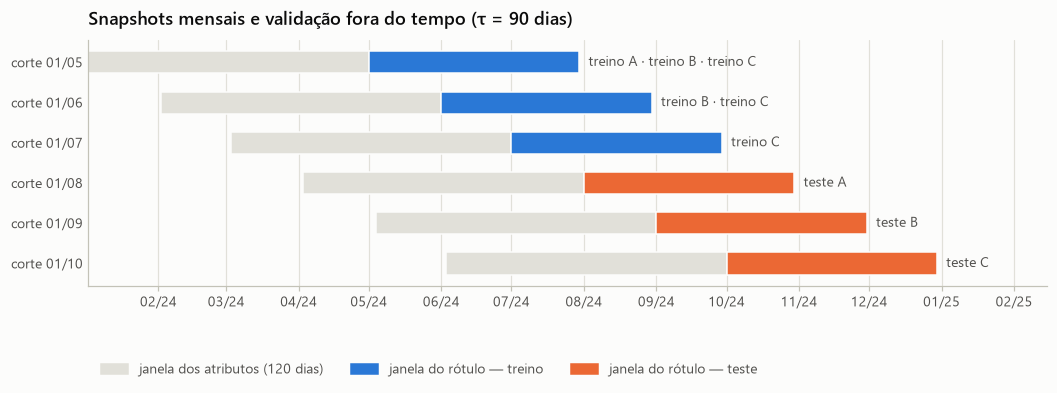

In [6]:
papeis = {c: [] for c in config.CORTES}
for nome, (treino, teste) in DOBRAS.items():
    for c in treino:
        papeis[c].append(f"treino {nome}")
    papeis[teste].append(f"teste {nome}")

fig, ax = plt.subplots(figsize=(9.5, 3.4))
for i, corte in enumerate(config.CORTES):
    eh_teste = any(p.startswith("teste") for p in papeis[corte])
    ax.barh(i, config.LOOKBACK, left=mdates.date2num(corte - pd.Timedelta(days=config.LOOKBACK)),
            height=0.55, color=viz.GRADE)
    ax.barh(i, TAU, left=mdates.date2num(corte), height=0.55, color=viz.LARANJA if eh_teste else viz.AZUL)
    ax.annotate(" · ".join(papeis[corte]), (mdates.date2num(corte + pd.Timedelta(days=TAU)), i),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=viz.TINTA_2)
ax.set_yticks(range(len(config.CORTES)), [f"corte {c:%d/%m}" for c in config.CORTES])
ax.invert_yaxis()
ax.xaxis_date()
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
ax.set_xlim(mdates.date2num(config.INICIO), mdates.date2num(pd.Timestamp("2025-02-15")))
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=viz.GRADE, label="janela dos atributos (120 dias)"),
                   Patch(color=viz.AZUL, label="janela do rótulo — treino"),
                   Patch(color=viz.LARANJA, label="janela do rótulo — teste")],
          loc="lower left", ncols=3, bbox_to_anchor=(0, -0.42))
viz.titulo(ax, "Snapshots mensais e validação fora do tempo (τ = 90 dias)")
viz.salvar(fig, "mod_esquema_validacao")
plt.show()

## 3. Linhas de base

**Heurística de recência (hiato).** A regra que um gestor usaria: quanto mais tempo sem comprar, maior o risco. O
score é simplesmente a recência em dias (Wübben & von Wangenheim, 2008).

**BG/NBD** (Fader, Hardie & Lee, 2005). Modelo probabilístico clássico para clientes não contratuais: enquanto ativo,
o cliente compra segundo um processo de Poisson com taxa λ ~ Gama(*r*, α); após cada compra, abandona a loja com
probabilidade *p* ~ Beta(*a*, *b*). Usa só três números por cliente — compras repetidas *x*, momento da última compra
*tₓ* e idade *T*, medidos em todo o histórico — e entrega, em forma fechada,

$$P(\text{nenhuma compra em } (T, T+\tau] \mid x, t_x, T) = 1 - P(\text{ativo}) + P(\text{ativo}) \left(\frac{\alpha + T}{\alpha + T + \tau}\right)^{r + x}.$$

O BG/NBD não usa o rótulo: é ajustado por máxima verossimilhança em cada data de corte, com os dados anteriores a ela
(implementação própria em `src/churn/bgnbd.py`).

In [7]:
parametros_bg = {}
snaps["bg_p_sem_compra"] = np.nan
snaps["bg_p_ativo"] = np.nan
modelos_bg = {}
for corte in config.CORTES:
    rfm = bgnbd.resumo_rfm(visitas, corte)
    modelo = bgnbd.BGNBD().fit(rfm["x"], rfm["t_x"], rfm["T"])
    modelos_bg[corte] = (modelo, rfm)
    parametros_bg[corte.strftime("%d/%m")] = {**modelo.params_, "clientes no ajuste": len(rfm), "log-verossimilhança": modelo.loglik_}
    idx = snaps["corte"] == corte
    r = rfm.loc[snaps.loc[idx, "CLI_CPF"]]
    snaps.loc[idx, "bg_p_sem_compra"] = modelo.p_sem_compra(TAU, r["x"], r["t_x"], r["T"])
    snaps.loc[idx, "bg_p_ativo"] = modelo.p_ativo(r["x"], r["t_x"], r["T"])
pd.DataFrame(parametros_bg).T

,r,alpha,a,b,clientes no ajuste,log-verossimilhança
01/05,"0,712","66,278","0,000","832,910",49.808,-208.656
01/06,"0,689","67,708","0,007","52,754",58.095,-296.872
01/07,"0,666","68,649","0,015","28,270",65.356,-388.748
01/08,"0,644","69,402","0,327","240,632",72.512,-489.358
01/09,"0,630","69,736","0,399","218,493",79.650,-600.082
01/10,"0,608","70,191","0,691","233,369",85.636,-704.756


Nos primeiros cortes o parâmetro *a* tende a zero: com poucos meses de histórico, os dados quase não distinguem
"abandonou" de "ainda não voltou", e o modelo se aproxima de um NBD puro. Com mais histórico (agosto em diante) o
componente de abandono passa a ser estimado.

**Checagem do BG/NBD (corte de 01/10):** comparamos o número médio de visitas previsto para os 90 dias seguintes com o
observado, agrupando os clientes pelo número de compras repetidas no histórico — o diagnóstico padrão desse modelo.

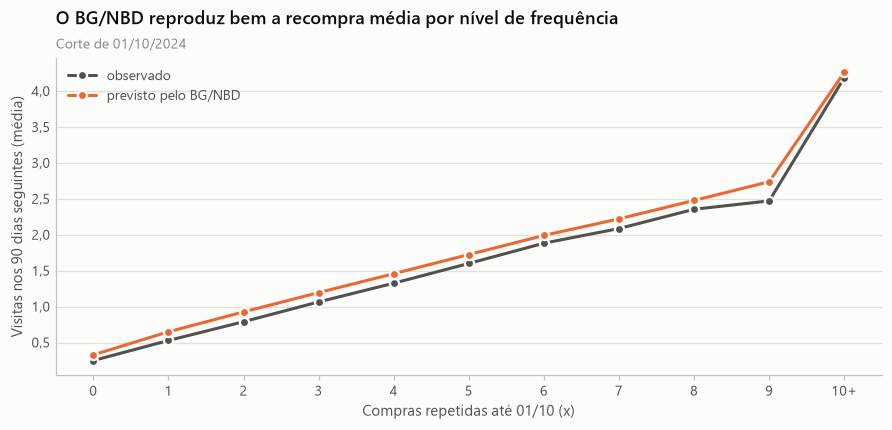

Total de visitas nos 90 dias: previsto 65.591 × observado 56.938


In [8]:
corte = pd.Timestamp("2024-10-01")
modelo, rfm = modelos_bg[corte]
futuras = visitas[(visitas["DATA_ATEND"] >= corte) & (visitas["DATA_ATEND"] < corte + pd.Timedelta(days=TAU))]
rfm = rfm.assign(
    previsto=modelo.compras_esperadas(TAU, rfm["x"], rfm["t_x"], rfm["T"]),
    observado=futuras.groupby("CLI_CPF").size().reindex(rfm.index, fill_value=0),
    grupo=np.minimum(rfm["x"], 10),
)
checagem = rfm.groupby("grupo")[["previsto", "observado"]].mean()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(checagem.index, checagem["observado"], color=viz.TINTA_2, marker="o", markeredgecolor=viz.SUPERFICIE,
        markeredgewidth=1.5, label="observado")
ax.plot(checagem.index, checagem["previsto"], color=viz.LARANJA, marker="o", markeredgecolor=viz.SUPERFICIE,
        markeredgewidth=1.5, label="previsto pelo BG/NBD")
ax.set_xticks(range(11), [*map(str, range(10)), "10+"])
ax.set_xlabel("Compras repetidas até 01/10 (x)")
ax.set_ylabel("Visitas nos 90 dias seguintes (média)")
ax.legend(loc="upper left")
viz.titulo(ax, "O BG/NBD reproduz bem a recompra média por nível de frequência", "Corte de 01/10/2024")
viz.salvar(fig, "mod_bgnbd_checagem")
plt.show()
print(f"Total de visitas nos 90 dias: previsto {viz.fmt_num(rfm['previsto'].sum())} × observado {viz.fmt_num(rfm['observado'].sum())}")

## 4. Modelos de aprendizado de máquina

Três famílias com vieses indutivos diferentes:

* **Regressão logística** (L2): linear no logit, interpretável. Atributos assimétricos em escala log, valores ausentes
  imputados pela mediana com indicador de ausência (os atributos de intervalo não existem para quem tem uma visita) e
  padronização — tudo dentro de um `Pipeline` do scikit-learn, ajustado só no treino.
* **Random forest**: média de árvores profundas com *bagging*; captura interações e não linearidades.
* **LightGBM** (Ke et al., 2017): *gradient boosting* de árvores, trata ausentes nativamente; hiperparâmetros por
  otimização bayesiana (TPE) com Optuna (Akiba et al., 2019), maximizando a AUC na validação interna, com *early stopping*.

Duas variações do LightGBM servem de **ablação**: só com atributos da janela de 120 dias (sem histórico acumulado) e
com as saídas do BG/NBD como atributos adicionais (modelo híbrido).

In [9]:
LOG = ["n_visitas", "visitas_0_30", "visitas_30_60", "visitas_60_90", "visitas_90_120", "ipt_medio", "ipt_ultimo",
       "atraso_relativo", "gasto_total", "ticket_medio", "itens_por_visita", "n_skus", "hist_visitas", "hist_dias", "hist_taxa"]
idx_log = [ATRIBUTOS.index(a) for a in LOG]


def log_seletivo(X):
    X = np.array(X, dtype=float, copy=True)
    X[:, idx_log] = np.log1p(X[:, idx_log])
    return X


def nova_logistica(C):
    return make_pipeline(
        FunctionTransformer(log_seletivo),
        SimpleImputer(strategy="median", add_indicator=True),
        StandardScaler(),
        LogisticRegression(C=C, max_iter=3000),
    )


def nova_floresta(min_folha, max_atrib):
    return make_pipeline(
        SimpleImputer(strategy="constant", fill_value=-1),
        RandomForestClassifier(n_estimators=300, min_samples_leaf=min_folha, max_features=max_atrib,
                               n_jobs=-1, random_state=SEED),
    )


treino_int = snaps[snaps["corte"] == "2024-05-01"]
valid_int = snaps[snaps["corte"] == "2024-06-01"]
X_tr, y_tr = treino_int[ATRIBUTOS], treino_int["churn"]
X_va, y_va = valid_int[ATRIBUTOS], valid_int["churn"]

busca_lr = {C: roc_auc_score(y_va, nova_logistica(C).fit(X_tr, y_tr).predict_proba(X_va)[:, 1])
            for C in [0.001, 0.01, 0.1, 1, 10]}
C_LR = max(busca_lr, key=busca_lr.get)

busca_rf = {(f, m): roc_auc_score(y_va, nova_floresta(f, m).fit(X_tr, y_tr).predict_proba(X_va)[:, 1])
            for f in [10, 30, 100] for m in ["sqrt", 0.3]}
FOLHA_RF, ATRIB_RF = max(busca_rf, key=busca_rf.get)

display(pd.concat({
    "Regressão logística (C)": pd.Series(busca_lr),
    "Random forest (min_samples_leaf, max_features)": pd.Series({str(k): v for k, v in busca_rf.items()}),
}).rename("AUC na validação interna").to_frame())
print(f"Escolhidos: C = {C_LR}; min_samples_leaf = {FOLHA_RF}, max_features = {ATRIB_RF}")

AUC na validação interna
Regressão logística (C)                        0,001                              0,739
                                               0,010                              0,739
                                               0,100                              0,735
                                               1,000                              0,734
                                               10,000                             0,734
Random forest (min_samples_leaf, max_features)  (10, 'sqrt')                      0,737
                                                (10, 0.3)                         0,739
                                                (30, 'sqrt')                      0,739
                                                (30, 0.3)                         0,739
                                                (100, 'sqrt')                     0,741
                                                (100, 0.3)                        0,740

Escolhidos: C = 0.01; min_samples_leaf = 100, max_features = sqrt


In [10]:
def objetivo(trial):
    params = dict(
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        num_leaves=trial.suggest_int("num_leaves", 8, 128, log=True),
        min_child_samples=trial.suggest_int("min_child_samples", 20, 1000, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.3, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 30, log=True),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
    )
    modelo = lgb.LGBMClassifier(n_estimators=3000, subsample_freq=1, random_state=SEED, verbose=-1,
                                deterministic=True, force_col_wise=True, **params)
    modelo.fit(X_tr, y_tr, eval_X=X_va, eval_y=y_va, eval_metric="auc",
               callbacks=[lgb.early_stopping(100, verbose=False)])
    trial.set_user_attr("n_estimators", int(modelo.best_iteration_))
    return roc_auc_score(y_va, modelo.predict_proba(X_va, num_iteration=modelo.best_iteration_)[:, 1])


estudo = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
estudo.optimize(objetivo, n_trials=40)
PARAMS_LGBM = {
    **estudo.best_params,
    "n_estimators": estudo.best_trial.user_attrs["n_estimators"],
    "subsample_freq": 1, "random_state": SEED, "verbose": -1, "deterministic": True, "force_col_wise": True,
}
print(f"Melhor AUC na validação interna: {viz.fmt_num(estudo.best_value, 4)} ({len(estudo.trials)} tentativas)")
pd.Series(PARAMS_LGBM, name="valor").to_frame()

Melhor AUC na validação interna: 0,7438 (40 tentativas)


,valor
learning_rate,"0,014"
num_leaves,79
min_child_samples,23
subsample,"0,948"
colsample_bytree,"0,341"
reg_lambda,"0,433"
reg_alpha,"0,244"
n_estimators,683
subsample_freq,1
random_state,42


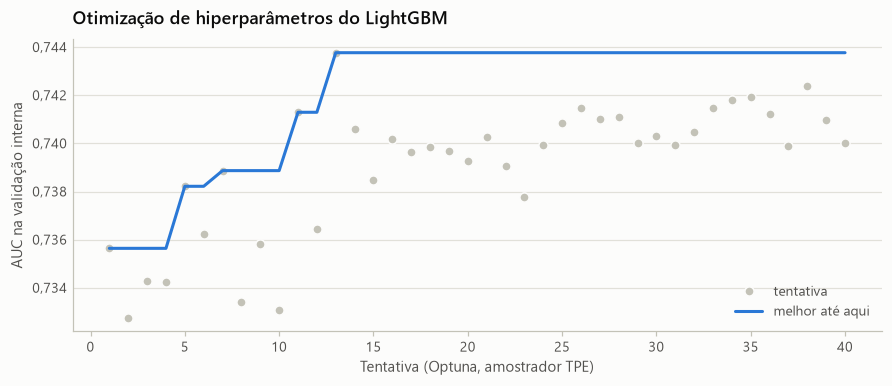

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.4))
valores = [t.value for t in estudo.trials]
ax.plot(range(1, len(valores) + 1), valores, linestyle="none", marker="o", color=viz.CONTEXTO,
        markeredgecolor=viz.SUPERFICIE, markeredgewidth=1, label="tentativa")
ax.plot(range(1, len(valores) + 1), np.maximum.accumulate(valores), color=viz.AZUL, label="melhor até aqui")
ax.set_xlabel("Tentativa (Optuna, amostrador TPE)")
ax.set_ylabel("AUC na validação interna")
ax.legend(loc="lower right")
viz.titulo(ax, "Otimização de hiperparâmetros do LightGBM")
viz.salvar(fig, "mod_optuna_historico")
plt.show()

### 4.1 Treino e previsão nas três dobras

In [12]:
ATRIB_HIBRIDO = ATRIBUTOS + ["bg_p_sem_compra", "bg_p_ativo"]
MODELOS = ["Recência (heurística)", "BG/NBD", "Regressão logística", "Random forest", "LightGBM",
           "LightGBM só janela", "LightGBM + BG/NBD"]
PROBABILISTICOS = [m for m in MODELOS if m != "Recência (heurística)"]

previsoes, ajustados = {}, {}
for nome, (cortes_treino, corte_teste) in DOBRAS.items():
    treino = snaps[snaps["corte"].isin(cortes_treino)]
    teste = snaps[snaps["corte"] == corte_teste]
    y = treino["churn"]
    m_lr = nova_logistica(C_LR).fit(treino[ATRIBUTOS], y)
    m_rf = nova_floresta(FOLHA_RF, ATRIB_RF).fit(treino[ATRIBUTOS], y)
    m_lgb = lgb.LGBMClassifier(**PARAMS_LGBM).fit(treino[ATRIBUTOS], y)
    m_jan = lgb.LGBMClassifier(**PARAMS_LGBM).fit(treino[features.ATRIBUTOS_JANELA], y)
    m_hib = lgb.LGBMClassifier(**PARAMS_LGBM).fit(treino[ATRIB_HIBRIDO], y)
    previsoes[nome] = pd.DataFrame({
        "CLI_CPF": teste["CLI_CPF"].to_numpy(),
        "churn": teste["churn"].to_numpy(),
        "segmento": teste["segmento"].to_numpy(),
        "Recência (heurística)": teste["recencia"].to_numpy(),
        "BG/NBD": teste["bg_p_sem_compra"].to_numpy(),
        "Regressão logística": m_lr.predict_proba(teste[ATRIBUTOS])[:, 1],
        "Random forest": m_rf.predict_proba(teste[ATRIBUTOS])[:, 1],
        "LightGBM": m_lgb.predict_proba(teste[ATRIBUTOS])[:, 1],
        "LightGBM só janela": m_jan.predict_proba(teste[features.ATRIBUTOS_JANELA])[:, 1],
        "LightGBM + BG/NBD": m_hib.predict_proba(teste[ATRIB_HIBRIDO])[:, 1],
    })
    ajustados[nome] = {"Regressão logística": m_lr, "Random forest": m_rf, "LightGBM": m_lgb}

ajustados["C"]["LightGBM"].booster_.save_model(str(config.MODELS_DIR / "lightgbm_tau90.txt"))
previsoes["C"].to_parquet(config.PROCESSED_DIR / "previsoes_teste_C.parquet", index=False)
print("Modelos treinados nas dobras:", ", ".join(DOBRAS))

Modelos treinados nas dobras: A, B, C


## 5. Avaliação fora do tempo (H10)

Métricas (aula de Análise de Desempenho, complementadas pela literatura de churn):

* **AUC-ROC**: probabilidade de um churner receber score maior que um não churner — independe de limiar;
* **PR-AUC** (precisão média): foco na classe positiva;
* **lift no decil superior**: quantas vezes a taxa de churn entre os 10% de maior risco supera a média (Neslin et
  al., 2006);
* **captura em 20%**: fração dos churners entre os 20% de maior risco — o que uma campanha que contata 20% da base alcança;
* **Brier e log-loss**: qualidade das probabilidades (calibração + discriminação). Não se aplicam à heurística de
  recência, que não é uma probabilidade.

In [13]:
linhas = []
for nome, prev in previsoes.items():
    for modelo in MODELOS:
        linhas.append({"dobra": nome, "modelo": modelo,
                       **ev.metricas(prev["churn"], prev[modelo], probabilidade=modelo in PROBABILISTICOS)})
metricas = pd.DataFrame(linhas).set_index(["dobra", "modelo"])
metricas.to_csv(config.TAB_DIR / "metricas_por_dobra.csv")
metricas.loc["C"]

,auc,pr_auc,lift_10,captura_20,brier,log_loss
modelo,,,,,,
Recência (heurística),"0,610","0,618","1,270","0,249",NaN,NaN
BG/NBD,"0,763","0,743","1,508","0,300","0,197","0,579"
Regressão logística,"0,770","0,754","1,535","0,301","0,200","0,586"
Random forest,"0,768","0,753","1,532","0,303","0,198","0,579"
LightGBM,"0,770","0,754","1,537","0,303","0,198","0,581"
LightGBM só janela,"0,729","0,704","1,418","0,278","0,205","0,596"
LightGBM + BG/NBD,"0,770","0,754","1,543","0,303","0,195","0,572"


In [14]:
prev_C = previsoes["C"]
boot = ev.bootstrap_auc(prev_C["churn"], {m: prev_C[m] for m in MODELOS}, referencia="BG/NBD", n_boot=1000, seed=SEED)
boot.to_csv(config.TAB_DIR / "auc_bootstrap_dobra_C.csv")
boot

,auc,ic95_inf,ic95_sup,dif_ref,dif_ic95_inf,dif_ic95_sup,p_valor
modelo,,,,,,,
Recência (heurística),"0,610","0,605","0,615","-0,152","-0,158","-0,148","0,000"
BG/NBD,"0,763","0,758","0,767",NaN,NaN,NaN,NaN
Regressão logística,"0,770","0,766","0,775","0,008","0,006","0,010","0,000"
Random forest,"0,768","0,764","0,773","0,006","0,004","0,008","0,000"
LightGBM,"0,770","0,766","0,775","0,007","0,006","0,009","0,000"
LightGBM só janela,"0,729","0,724","0,734","-0,034","-0,037","-0,030","0,000"
LightGBM + BG/NBD,"0,770","0,766","0,775","0,008","0,006","0,010","0,000"


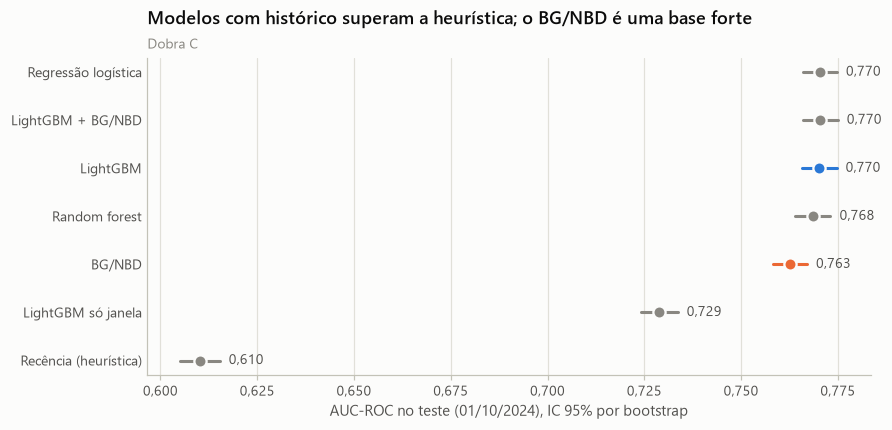

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ordem = boot.sort_values("auc").index
for i, modelo in enumerate(ordem):
    linha = boot.loc[modelo]
    cor = viz.AZUL if modelo == "LightGBM" else (viz.LARANJA if modelo == "BG/NBD" else viz.TINTA_SUAVE)
    ax.plot([linha["ic95_inf"], linha["ic95_sup"]], [i, i], color=cor, linewidth=2)
    ax.plot(linha["auc"], i, marker="o", markersize=8, color=cor, markeredgecolor=viz.SUPERFICIE, markeredgewidth=1.5)
    ax.annotate(viz.fmt_num(linha["auc"], 3), (linha["ic95_sup"], i), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=viz.TINTA_2)
ax.set_yticks(range(len(ordem)), ordem)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("AUC-ROC no teste (01/10/2024), IC 95% por bootstrap")
viz.titulo(ax, "Modelos com histórico superam a heurística; o BG/NBD é uma base forte", "Dobra C")
viz.salvar(fig, "mod_auc_modelos")
plt.show()

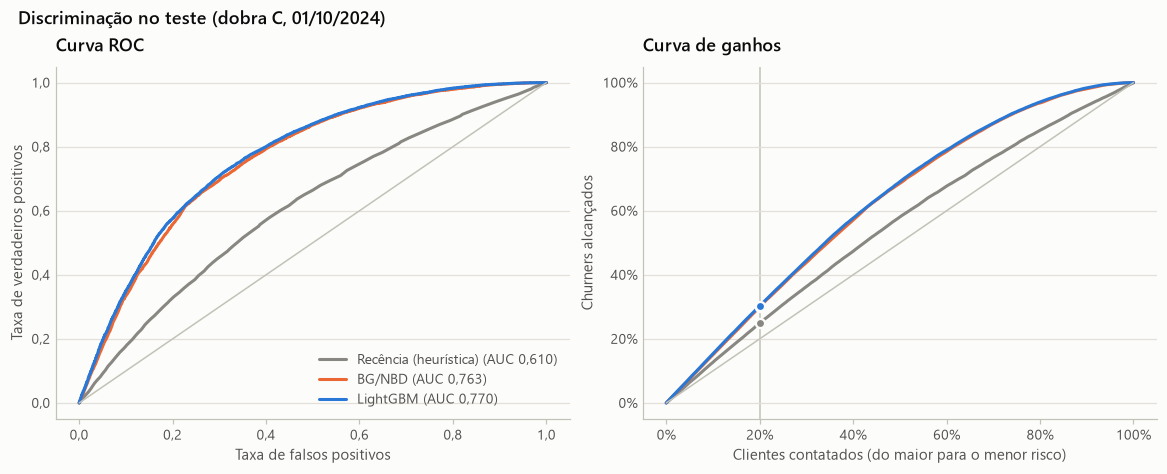

In [16]:
destaque = {"Recência (heurística)": viz.TINTA_SUAVE, "BG/NBD": viz.LARANJA, "LightGBM": viz.AZUL}
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
ax = axes[0]
for modelo, cor in destaque.items():
    fpr, tpr, _ = roc_curve(prev_C["churn"], prev_C[modelo])
    ax.plot(fpr, tpr, color=cor, label=f"{modelo} (AUC {viz.fmt_num(boot.loc[modelo, 'auc'], 3)})")
ax.plot([0, 1], [0, 1], color=viz.CONTEXTO, linewidth=1)
ax.set_xlabel("Taxa de falsos positivos")
ax.set_ylabel("Taxa de verdadeiros positivos")
ax.legend(loc="lower right")
viz.titulo(ax, "Curva ROC")

ax = axes[1]
for modelo, cor in destaque.items():
    x, y = ev.curva_ganhos(prev_C["churn"], prev_C[modelo])
    ax.plot(x, y, color=cor, label=modelo)
ax.plot([0, 1], [0, 1], color=viz.CONTEXTO, linewidth=1)
x20 = 0.2
for modelo, cor in destaque.items():
    y20 = ev.captura(prev_C["churn"], prev_C[modelo], x20)
    ax.plot([x20], [y20], marker="o", color=cor, markeredgecolor=viz.SUPERFICIE, markeredgewidth=1.5)
ax.axvline(x20, color=viz.CONTEXTO, linewidth=1, zorder=0)
ax.xaxis.set_major_formatter(viz.PCT)
ax.yaxis.set_major_formatter(viz.PCT)
ax.set_xlabel("Clientes contatados (do maior para o menor risco)")
ax.set_ylabel("Churners alcançados")
viz.titulo(ax, "Curva de ganhos")
fig.suptitle("Discriminação no teste (dobra C, 01/10/2024)", x=0.01, ha="left", fontsize=12, fontweight="semibold")
viz.salvar(fig, "mod_roc_ganhos")
plt.show()

### 5.1 Calibração e limiar de decisão

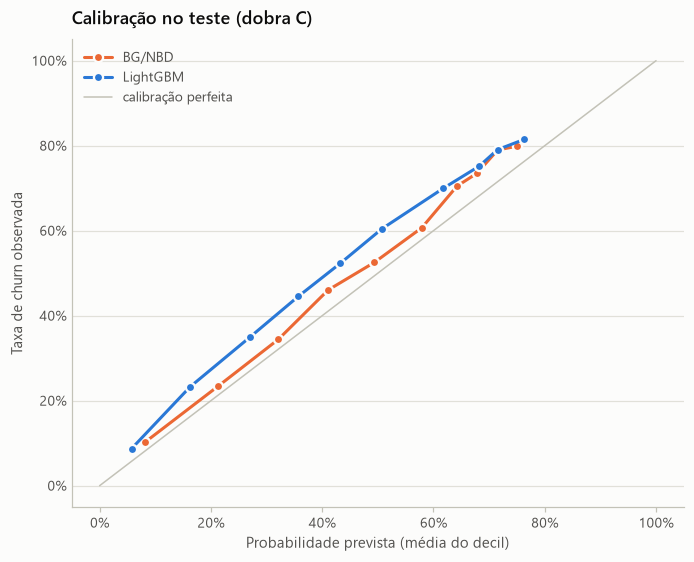

Churn observado: 53,0% | previsto em média: BG/NBD 48,8%, LightGBM 45,7%, LightGBM + BG/NBD 48,3%


,clientes,churn_observado,LightGBM,BG_NBD
faixa,,,,
até 60 dias,12834,"0,739","0,670","0,641"
61–120 dias,9159,"0,676","0,577","0,602"
121–181 dias,5531,"0,458","0,372","0,423"
182–273 dias (além do treino),18775,"0,338","0,277","0,347"


In [17]:
fig, ax = plt.subplots(figsize=(6.2, 5))
for modelo, cor in [("BG/NBD", viz.LARANJA), ("LightGBM", viz.AZUL)]:
    obs, prev = calibration_curve(prev_C["churn"], prev_C[modelo], n_bins=10, strategy="quantile")
    ax.plot(prev, obs, color=cor, marker="o", markeredgecolor=viz.SUPERFICIE, markeredgewidth=1.5, label=modelo)
ax.plot([0, 1], [0, 1], color=viz.CONTEXTO, linewidth=1, label="calibração perfeita")
ax.set_xlabel("Probabilidade prevista (média do decil)")
ax.set_ylabel("Taxa de churn observada")
ax.xaxis.set_major_formatter(viz.PCT)
ax.yaxis.set_major_formatter(viz.PCT)
ax.legend(loc="upper left")
viz.titulo(ax, "Calibração no teste (dobra C)")
viz.salvar(fig, "mod_calibracao")
plt.show()

media_prev = prev_C[["churn", "BG/NBD", "LightGBM", "LightGBM + BG/NBD"]].mean()
print(f"Churn observado: {viz.fmt_pct(media_prev['churn'], 1)} | previsto em média: "
      f"BG/NBD {viz.fmt_pct(media_prev['BG/NBD'], 1)}, LightGBM {viz.fmt_pct(media_prev['LightGBM'], 1)}, "
      f"LightGBM + BG/NBD {viz.fmt_pct(media_prev['LightGBM + BG/NBD'], 1)}")

teste_hist = snaps.loc[snaps["corte"] == DOBRAS["C"][1], ["hist_dias"]].reset_index(drop=True)
faixa_hist = pd.cut(teste_hist["hist_dias"], [0, 60, 120, 181, 273],
                    labels=["até 60 dias", "61–120 dias", "121–181 dias", "182–273 dias (além do treino)"])
prev_C.assign(faixa=faixa_hist).groupby("faixa", observed=True).agg(
    clientes=("churn", "size"), churn_observado=("churn", "mean"), LightGBM=("LightGBM", "mean"), BG_NBD=("BG/NBD", "mean")
)

**Deriva temporal.** Os dois modelos ordenam bem os clientes, mas **subestimam o nível** de churn no teste: o risco
condicional subiu no último trimestre em relação aos meses de treino. No LightGBM há um agravante, visível na tabela
acima: em 01/10 o histórico observável chega a 273 dias, mas nos cortes de treino não passava de 181, então clientes
antigos são extrapolados como se fossem ainda mais fiéis (efeito da truncagem à esquerda). O modelo híbrido, que recebe
a P(sem compra) do BG/NBD — que trata a idade do cliente de forma explícita —, tem a melhor calibração (Brier e
log-loss). Para uso real, a ordenação é o que importa para priorizar contatos, mas as probabilidades devem ser
recalibradas periodicamente.

In [18]:
limiar = 0.5
pred = (prev_C["LightGBM"] >= limiar).astype(int)
vn, fp, fn, vp = confusion_matrix(prev_C["churn"], pred).ravel()
display(pd.DataFrame([[vn, fp], [fn, vp]], index=["real: ativo", "real: churn"], columns=["previsto: ativo", "previsto: churn"]))
pd.Series({
    "acurácia": (vp + vn) / len(pred),
    "precisão": vp / (vp + fp),
    "revocação (sensibilidade)": vp / (vp + fn),
    "especificidade": vn / (vn + fp),
    "F1": 2 * vp / (2 * vp + fp + fn),
}, name=f"LightGBM, limiar {viz.fmt_num(limiar, 1)}").to_frame()

,previsto: ativo,previsto: churn
real: ativo,16344,5419
real: churn,8697,15839


,"LightGBM, limiar 0,5"
acurácia,"0,695"
precisão,"0,745"
revocação (sensibilidade),"0,646"
especificidade,"0,751"
F1,"0,692"


### 5.2 Estabilidade entre dobras e desempenho por segmento

modelo,Recência (heurística),BG/NBD,Regressão logística,Random forest,LightGBM,LightGBM só janela,LightGBM + BG/NBD
A (teste 01/08),"0,602","0,757","0,757","0,754","0,747","0,733","0,748"
B (teste 01/09),"0,609","0,764","0,772","0,769","0,771","0,734","0,772"
C (teste 01/10),"0,610","0,763","0,770","0,768","0,770","0,729","0,770"


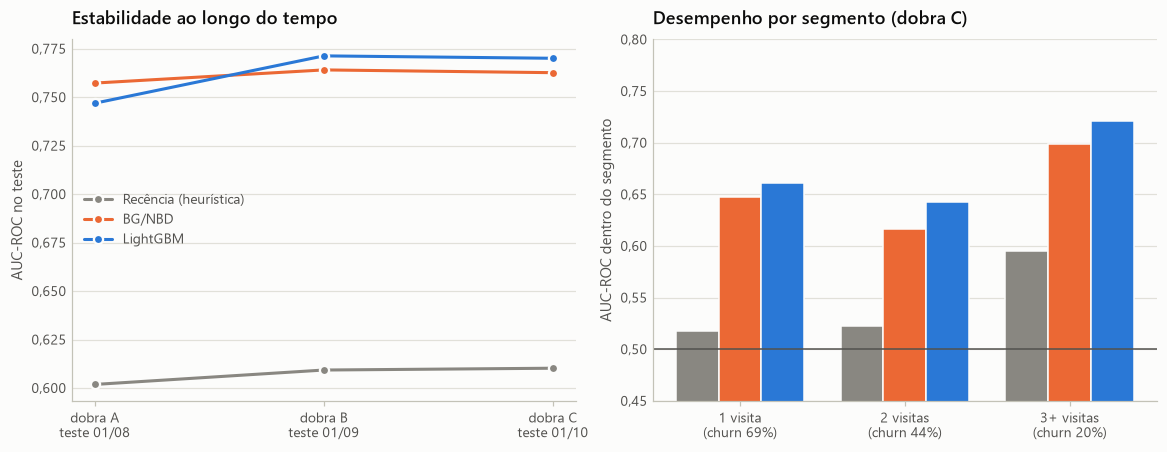

In [19]:
auc_dobras = metricas["auc"].unstack("modelo")[MODELOS]
auc_dobras.index = [f"{n} (teste {DOBRAS[n][1]:%d/%m})" for n in auc_dobras.index]
display(auc_dobras)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))
ax = axes[0]
x = np.arange(len(auc_dobras))
for modelo, cor in destaque.items():
    ax.plot(x, auc_dobras[modelo], color=cor, marker="o", markeredgecolor=viz.SUPERFICIE, markeredgewidth=1.5, label=modelo)
ax.set_xticks(x, [f"dobra {n}\nteste {DOBRAS[n][1]:%d/%m}" for n in DOBRAS])
ax.set_ylabel("AUC-ROC no teste")
ax.legend(loc="center left")
viz.titulo(ax, "Estabilidade ao longo do tempo")

ax = axes[1]
segs = ["1 visita", "2 visitas", "3+ visitas"]
largura = 0.26
for k, (modelo, cor) in enumerate(destaque.items()):
    aucs = [roc_auc_score(d["churn"], d[modelo]) for s in segs for d in [prev_C[prev_C["segmento"] == s]]]
    ax.bar(np.arange(3) + (k - 1) * largura, aucs, width=largura, color=cor, label=modelo)
ax.axhline(0.5, color=viz.TINTA_2, linewidth=1)
ax.set_xticks(range(3), [f"{s}\n(churn {viz.fmt_pct(prev_C.loc[prev_C['segmento'] == s, 'churn'].mean())})" for s in segs])
ax.set_ylim(0.45, 0.8)
ax.set_ylabel("AUC-ROC dentro do segmento")
viz.titulo(ax, "Desempenho por segmento (dobra C)")
viz.salvar(fig, "mod_estabilidade_segmentos")
plt.show()

## 6. Interpretação (H3–H9)

Duas lentes complementares (Shmueli, 2010, distingue modelos para *explicar* e para *prever*):

* **SHAP** (Lundberg & Lee, 2017) no LightGBM da dobra C: quanto cada atributo empurra o log-odds de churn de cada
  cliente, capturando não linearidades e interações;
* **regressão logística explicativa** (statsmodels) no treino da dobra C, com erros-padrão robustos agrupados por
  cliente (o mesmo cliente aparece em vários snapshots) e efeitos fixos de corte. As razões de chance são por desvio
  padrão de cada atributo, o que permite comparar magnitudes.

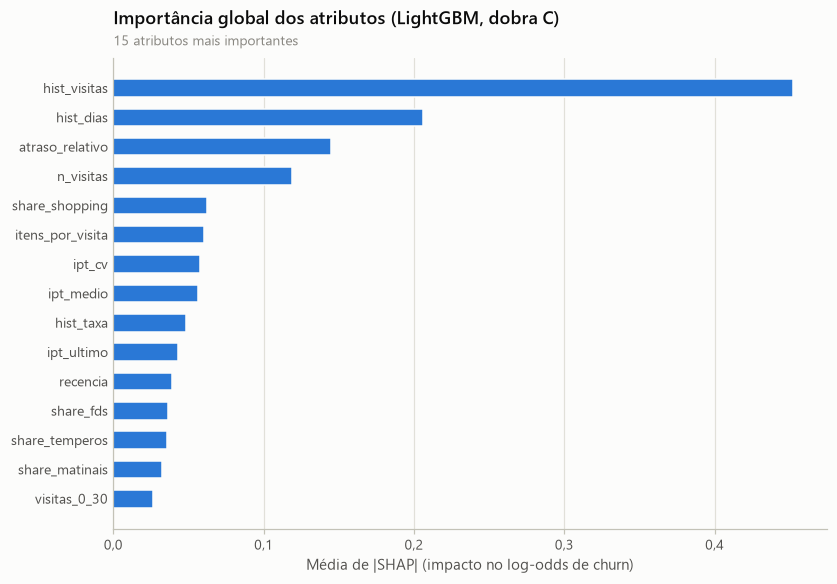

In [20]:
teste_C = snaps[snaps["corte"] == DOBRAS["C"][1]].reset_index(drop=True)
amostra = teste_C.sample(5000, random_state=SEED)
explicador = shap.TreeExplainer(ajustados["C"]["LightGBM"])
valores_shap = explicador(amostra[ATRIBUTOS])
if valores_shap.values.ndim == 3:
    valores_shap = valores_shap[:, :, 1]

importancia = pd.Series(np.abs(valores_shap.values).mean(axis=0), index=ATRIBUTOS).sort_values(ascending=False)
importancia.rename("média |SHAP|").to_csv(config.TAB_DIR / "importancia_shap.csv")

top = importancia.head(15).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 5.2))
ax.barh(top.index, top.values, color=viz.AZUL, height=0.6)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("Média de |SHAP| (impacto no log-odds de churn)")
viz.titulo(ax, "Importância global dos atributos (LightGBM, dobra C)", "15 atributos mais importantes")
viz.salvar(fig, "mod_shap_importancia")
plt.show()

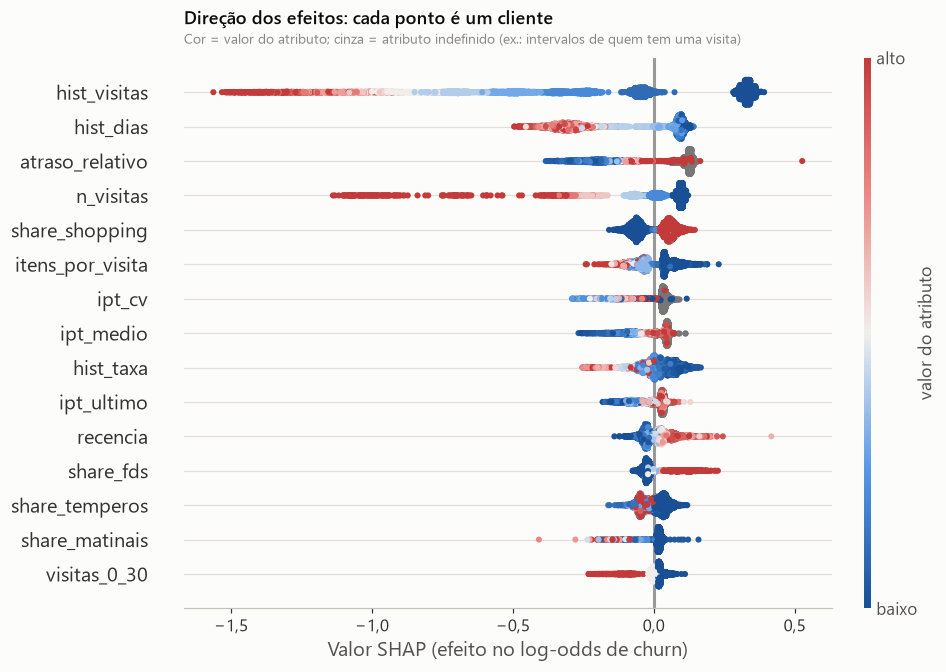

In [21]:
plt.figure()
shap.plots.beeswarm(valores_shap, max_display=15, color=viz.CMAP_DIV, show=False, plot_size=(8.5, 6),
                    color_bar_label="valor do atributo", group_remaining_features=False)
fig = plt.gcf()
ax, barra = fig.axes[0], fig.axes[-1]
barra.set_yticklabels(["baixo", "alto"])
ax.set_xlabel("Valor SHAP (efeito no log-odds de churn)")
viz.titulo(ax, "Direção dos efeitos: cada ponto é um cliente",
           "Cor = valor do atributo; cinza = atributo indefinido (ex.: intervalos de quem tem uma visita)")
viz.salvar(fig, "mod_shap_beeswarm")
plt.show()

**Cuidado ao ler o SHAP:** com atributos correlacionados, a importância se distribui de forma um tanto arbitrária
entre eles — `atraso_relativo` aparece alto, mas recência, intervalos e frequência carregam quase a mesma informação.
Por isso a seção 6.1 mede a **informação única** de cada bloco por ablação.

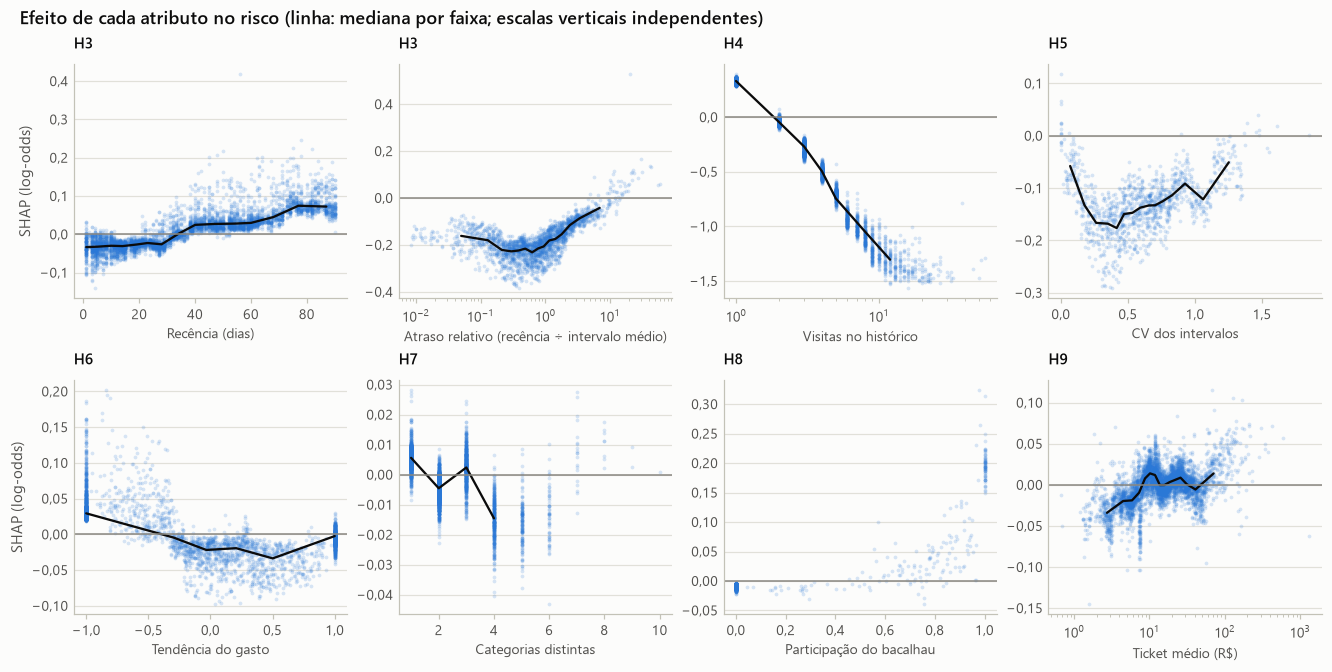

In [22]:
dependencias = [
    ("recencia", "Recência (dias)", "H3"),
    ("atraso_relativo", "Atraso relativo (recência ÷ intervalo médio)", "H3"),
    ("hist_visitas", "Visitas no histórico", "H4"),
    ("ipt_cv", "CV dos intervalos", "H5"),
    ("tend_gasto", "Tendência do gasto", "H6"),
    ("n_categorias", "Categorias distintas", "H7"),
    ("share_bacalhau", "Participação do bacalhau", "H8"),
    ("ticket_medio", "Ticket médio (R$)", "H9"),
]
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, (atrib, rotulo, hip) in zip(axes.flat, dependencias):
    j = ATRIBUTOS.index(atrib)
    xv = amostra[atrib].to_numpy(dtype=float)
    sv = valores_shap.values[:, j]
    ok = ~np.isnan(xv)
    ax.scatter(xv[ok], sv[ok], s=6, color=viz.AZUL, alpha=0.18, linewidths=0)
    if atrib in ("atraso_relativo", "hist_visitas", "ticket_medio"):
        ax.set_xscale("log")
    bordas = np.unique(np.quantile(xv[ok], np.linspace(0, 1, 16)))
    if len(bordas) > 2:
        grupo = np.clip(np.searchsorted(bordas, xv[ok], side="right") - 1, 0, len(bordas) - 2)
        medias = pd.DataFrame({"x": xv[ok], "s": sv[ok], "g": grupo}).groupby("g").median()
        ax.plot(medias["x"], medias["s"], color=viz.TINTA, linewidth=1.5)
    ax.axhline(0, color=viz.TINTA_SUAVE, linewidth=1)
    ax.set_xlabel(rotulo, fontsize=9)
    ax.set_title(hip, loc="left", fontsize=10)
for ax in axes[:, 0]:
    ax.set_ylabel("SHAP (log-odds)")
fig.suptitle("Efeito de cada atributo no risco (linha: mediana por faixa; escalas verticais independentes)",
             x=0.01, ha="left", fontsize=12, fontweight="semibold")
viz.salvar(fig, "mod_shap_dependencia")
plt.show()

### 6.1 Ablação por bloco de hipótese

Retreinamos o LightGBM da dobra C removendo, um de cada vez, o bloco de atributos ligado a cada hipótese, e medimos a
queda de AUC no teste (IC 95% por bootstrap pareado). Uma queda próxima de zero significa que o bloco não traz
informação que os demais já não tenham — mesmo que esteja associado ao churn.

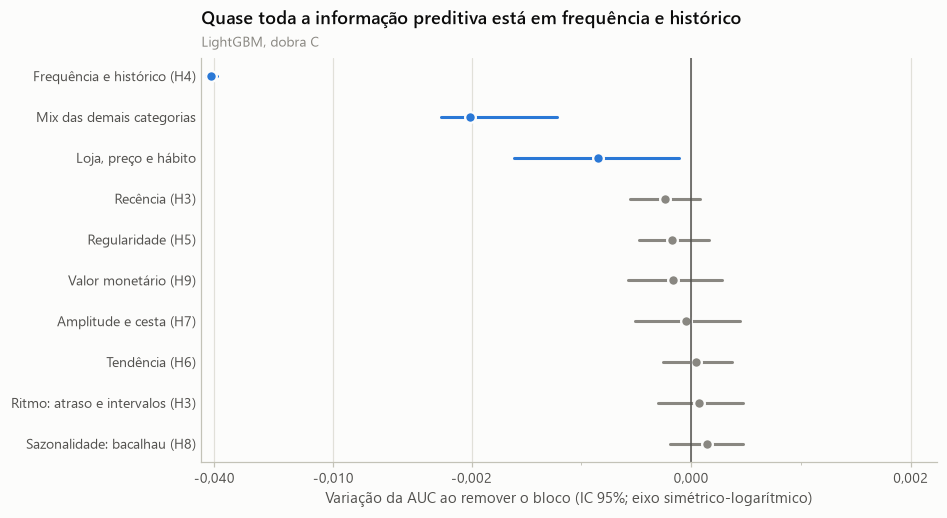

,auc,ic95_inf,ic95_sup,dif_ref,dif_ic95_inf,dif_ic95_sup,p_valor
modelo,,,,,,,
Modelo completo,"0,770","0,766","0,775",NaN,NaN,NaN,NaN
Recência (H3),"0,770","0,765","0,774","-0,000","-0,001","0,000","0,148"
Ritmo: atraso e intervalos (H3),"0,770","0,766","0,775","0,000","-0,000","0,000","0,748"
Frequência e histórico (H4),"0,729","0,724","0,733","-0,041","-0,044","-0,039","0,000"
Regularidade (H5),"0,770","0,766","0,775","-0,000","-0,000","0,000","0,268"
Tendência (H6),"0,770","0,766","0,775","0,000","-0,000","0,000","0,760"
Amplitude e cesta (H7),"0,770","0,766","0,775","-0,000","-0,001","0,000","0,756"
Sazonalidade: bacalhau (H8),"0,770","0,766","0,775","0,000","-0,000","0,000","0,372"
Valor monetário (H9),"0,770","0,766","0,775","-0,000","-0,001","0,000","0,432"


In [23]:
outros_mix = [c for c in features.CATEGORIAS.values() if c != "share_bacalhau"]
BLOCOS = {
    "Recência (H3)": ["recencia"],
    "Ritmo: atraso e intervalos (H3)": ["atraso_relativo", "ipt_medio", "ipt_ultimo"],
    "Frequência e histórico (H4)": ["n_visitas", "visitas_0_30", "visitas_30_60", "visitas_60_90", "visitas_90_120",
                                    "dias_desde_primeira", "hist_visitas", "hist_dias", "hist_taxa"],
    "Regularidade (H5)": ["ipt_cv"],
    "Tendência (H6)": ["tend_visitas", "tend_gasto"],
    "Amplitude e cesta (H7)": ["n_categorias", "entropia_categorias", "n_skus", "itens_por_visita"],
    "Sazonalidade: bacalhau (H8)": ["share_bacalhau"],
    "Valor monetário (H9)": ["gasto_total", "ticket_medio"],
    "Mix das demais categorias": outros_mix,
    "Loja, preço e hábito": ["share_desconto", "share_shopping", "multiloja", "share_fds"],
}
assert sorted(sum(BLOCOS.values(), [])) == sorted(ATRIBUTOS)

treino_abl = snaps[snaps["corte"].isin(DOBRAS["C"][0])]
scores_abl = {"Modelo completo": prev_C["LightGBM"].to_numpy()}
for bloco, removidos in BLOCOS.items():
    mantidos = [a for a in ATRIBUTOS if a not in removidos]
    modelo = lgb.LGBMClassifier(**PARAMS_LGBM).fit(treino_abl[mantidos], treino_abl["churn"])
    scores_abl[bloco] = modelo.predict_proba(teste_C[mantidos])[:, 1]
ablacao = ev.bootstrap_auc(prev_C["churn"], scores_abl, referencia="Modelo completo", n_boot=500, seed=SEED)
ablacao.to_csv(config.TAB_DIR / "ablacao_blocos.csv")

tab = ablacao.drop("Modelo completo").sort_values("dif_ref")
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for i, (bloco, linha) in enumerate(tab.iterrows()):
    cor = viz.AZUL if linha["dif_ic95_sup"] < 0 else viz.TINTA_SUAVE
    ax.plot([linha["dif_ic95_inf"], linha["dif_ic95_sup"]], [i, i], color=cor, linewidth=2)
    ax.plot(linha["dif_ref"], i, marker="o", markersize=7, color=cor, markeredgecolor=viz.SUPERFICIE, markeredgewidth=1.5)
ax.axvline(0, color=viz.TINTA_2, linewidth=1)
ax.set_yticks(range(len(tab)), tab.index)
ax.invert_yaxis()
ax.set_xscale("symlog", linthresh=0.002)
ax.set_xticks([-0.04, -0.01, -0.002, 0, 0.002])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: viz.fmt_num(x, 3)))
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("Variação da AUC ao remover o bloco (IC 95%; eixo simétrico-logarítmico)")
viz.titulo(ax, "Quase toda a informação preditiva está em frequência e histórico", "LightGBM, dobra C")
viz.salvar(fig, "mod_ablacao_blocos")
plt.show()
ablacao

In [24]:
treino_C = snaps[snaps["corte"].isin(DOBRAS["C"][0])].reset_index(drop=True)


def ajustar_explicativo(df, variaveis):
    X = pd.DataFrame(variaveis)
    Z = (X - X.mean()) / X.std()
    efeitos_corte = pd.get_dummies(df["corte"].dt.strftime("corte_%m"), drop_first=True, dtype=float)
    Z = sm.add_constant(pd.concat([Z, efeitos_corte], axis=1))
    grupos = pd.factorize(df["CLI_CPF"])[0]
    res = sm.Logit(df["churn"].to_numpy(), Z).fit(disp=0, cov_type="cluster", cov_kwds={"groups": grupos})
    ic = np.exp(res.conf_int())
    tab = pd.DataFrame({"OR por 1 DP": np.exp(res.params), "IC95 inf": ic[0], "IC95 sup": ic[1], "p-valor": res.pvalues})
    return tab.loc[X.columns], res, X


def variaveis_base(d):
    return {
        "recência (dias)": d["recencia"],
        "visitas na janela (log)": np.log1p(d["n_visitas"]),
        "antiguidade observada (dias)": d["hist_dias"],
        "tendência do gasto": d["tend_gasto"],
        "categorias distintas": d["n_categorias"],
        "participação do bacalhau": d["share_bacalhau"],
        "ticket médio (log)": np.log(d["ticket_medio"]),
        "itens com desconto": d["share_desconto"],
        "visitas no shopping": d["share_shopping"],
        "visitas no fim de semana": d["share_fds"],
    }


or_e1, res_e1, X_e1 = ajustar_explicativo(treino_C, variaveis_base(treino_C))
rec3 = treino_C[treino_C["n_visitas"] >= 3].reset_index(drop=True)
or_e2, res_e2, X_e2 = ajustar_explicativo(rec3, {
    **variaveis_base(rec3),
    "intervalo médio entre visitas (log)": np.log(rec3["ipt_medio"]),
    "CV dos intervalos": rec3["ipt_cv"],
})
vif = pd.Series([variance_inflation_factor(sm.add_constant(X_e1).to_numpy(), i + 1) for i in range(X_e1.shape[1])],
                index=X_e1.columns, name="VIF")
print(f"E1: todos os clientes ativos (n = {viz.fmt_num(len(treino_C))}, pseudo-R² = {viz.fmt_num(res_e1.prsquared, 3)}) | "
      f"E2: clientes com 3+ visitas (n = {viz.fmt_num(len(rec3))}, pseudo-R² = {viz.fmt_num(res_e2.prsquared, 3)}) | "
      f"VIF máximo em E1 = {viz.fmt_num(vif.max(), 1)}")
explicativos = pd.concat({"E1 (todos)": or_e1, "E2 (3+ visitas)": or_e2})
explicativos.to_csv(config.TAB_DIR / "logistica_explicativa_or.csv")
explicativos

E1: todos os clientes ativos (n = 128.941, pseudo-R² = 0,147) | E2: clientes com 3+ visitas (n = 27.325, pseudo-R² = 0,088) | VIF máximo em E1 = 2,8


OR por 1 DP  IC95 inf  IC95 sup  p-valor
E1 (todos)      recência (dias)                            1,163     1,139     1,187    0,000
                visitas na janela (log)                    0,491     0,477     0,505    0,000
                antiguidade observada (dias)               0,687     0,673     0,701    0,000
                tendência do gasto                         0,919     0,903     0,934    0,000
                categorias distintas                       0,907     0,887     0,927    0,000
                participação do bacalhau                   1,072     1,052     1,092    0,000
                ticket médio (log)                         1,013     0,993     1,034    0,190
                itens com desconto                         1,009     0,994     1,025    0,252
                visitas no shopping                        1,077     1,060     1,094    0,000
                visitas no fim de semana                   1,065     1,049     1,082    0,000
E2 (3+ visitas) recência (dias)                            1,265     1,203     1,331    0,000
                visitas na janela (log)                    0,557     0,510     0,608    0,000
                antiguidade observada (dias)               0,678     0,643     0,715    0,000
                tendência do gasto                         0,909     0,873     0,946    0,000
                categorias distintas                       0,913     0,872     0,955    0,000
                participação do bacalhau                   1,069     1,026     1,113    0,001
                ticket médio (log)                         0,939     0,898     0,982    0,006
                itens com desconto                         1,036     0,997     1,076    0,069
                visitas no shopping                        1,070     1,030     1,112    0,000
                visitas no fim de semana                   1,029     0,993     1,066    0,119
                intervalo médio entre visitas (log)        1,170     1,101     1,245    0,000
                CV dos intervalos                          1,038     1,002     1,075    0,039

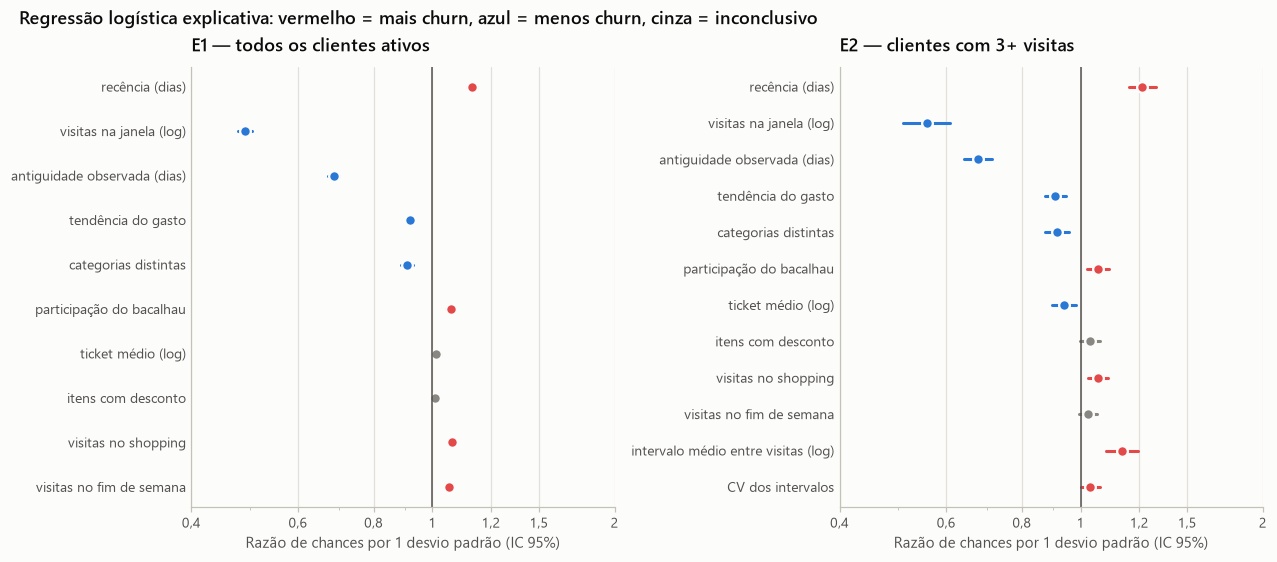

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5), sharex=True)
for ax, (titulo, tab) in zip(axes, [("E1 — todos os clientes ativos", or_e1), ("E2 — clientes com 3+ visitas", or_e2)]):
    tab = tab.iloc[::-1]
    for i, (var, linha) in enumerate(tab.iterrows()):
        if linha["IC95 inf"] > 1:
            cor = viz.VERMELHO
        elif linha["IC95 sup"] < 1:
            cor = viz.AZUL
        else:
            cor = viz.TINTA_SUAVE
        ax.plot([linha["IC95 inf"], linha["IC95 sup"]], [i, i], color=cor, linewidth=2)
        ax.plot(linha["OR por 1 DP"], i, marker="o", markersize=7, color=cor, markeredgecolor=viz.SUPERFICIE, markeredgewidth=1.5)
    ax.axvline(1, color=viz.TINTA_2, linewidth=1)
    ax.set_yticks(range(len(tab)), tab.index)
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(viz.NUM)
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_xticks([0.4, 0.6, 0.8, 1, 1.25, 1.5, 2])
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_xlabel("Razão de chances por 1 desvio padrão (IC 95%)")
    viz.titulo(ax, titulo)
fig.suptitle("Regressão logística explicativa: vermelho = mais churn, azul = menos churn, cinza = inconclusivo",
             x=0.01, ha="left", fontsize=12, fontweight="semibold")
viz.salvar(fig, "mod_logistica_or")
plt.show()

**Teste direto da H3.** Entre clientes com 3+ visitas, ajustamos a mesma regressão explicativa trocando a recência
absoluta pela relativa (ambas em log). Se o ritmo individual importasse, o modelo com atraso relativo teria AIC menor.

In [26]:
def especificacao_h3(d, relativa):
    v = variaveis_base(d)
    v.pop("recência (dias)")
    if relativa:
        v["atraso relativo (log)"] = np.log(d["atraso_relativo"])
    else:
        v["recência (log)"] = np.log(d["recencia"])
    v["CV dos intervalos"] = d["ipt_cv"]
    return v


comparacao_h3 = {}
for nome, relativa, coluna in [("recência absoluta", False, "recencia"), ("atraso relativo", True, "atraso_relativo")]:
    _, res, _ = ajustar_explicativo(rec3, especificacao_h3(rec3, relativa))
    comparacao_h3[nome] = {
        "AUC univariada": ev.auc_univariada(rec3["churn"], rec3[coluna]),
        "AIC do modelo multivariado": res.aic,
        "AUC do modelo multivariado": roc_auc_score(rec3["churn"], res.predict()),
    }
pd.DataFrame(comparacao_h3).T

,AUC univariada,AIC do modelo multivariado,AUC do modelo multivariado
recência absoluta,"0,592",24.343,"0,701"
atraso relativo,"0,545",24.350,"0,701"


## 7. Sensibilidade ao critério de inatividade (H2)

Refazemos rótulos e base ativa com τ = 60, 90 e 120 dias, mantendo os mesmos atributos (que não dependem de τ) e o
mesmo desenho: treino em 01/05 e teste em 01/09 — o único par de cortes válido para os três limiares. Além do
desempenho, medimos se os modelos **ordenam os clientes da mesma forma**: correlação de Spearman entre os scores,
sobreposição dos 10% de maior risco e uma matriz cruzada (modelo treinado com τᵢ avaliado no rótulo de τⱼ).

In [27]:
corte_tr, corte_te = pd.Timestamp("2024-05-01"), pd.Timestamp("2024-09-01")
sens, modelos_tau, testes_tau = [], {}, {}
modelo_bg, rfm_te = modelos_bg[corte_te]
for tau in config.TAUS_SENSIBILIDADE:
    tr = features.construir_snapshot(itens, visitas, corte_tr, tau=tau)
    te = features.construir_snapshot(itens, visitas, corte_te, tau=tau)
    m = lgb.LGBMClassifier(**PARAMS_LGBM).fit(tr[ATRIBUTOS], tr["churn"])
    r = rfm_te.loc[te["CLI_CPF"]]
    scores = {
        "Recência (heurística)": te["recencia"],
        "BG/NBD": modelo_bg.p_sem_compra(tau, r["x"], r["t_x"], r["T"]),
        "LightGBM": m.predict_proba(te[ATRIBUTOS])[:, 1],
    }
    modelos_tau[tau], testes_tau[tau] = m, te
    sens.append({"τ (dias)": tau, "base ativa (teste)": len(te), "prevalência": te["churn"].mean(),
                 **{f"AUC {k}": roc_auc_score(te["churn"], v) for k, v in scores.items()},
                 "lift@10 LightGBM": ev.lift(te["churn"], scores["LightGBM"])})
sens = pd.DataFrame(sens).set_index("τ (dias)")
sens.to_csv(config.TAB_DIR / "sensibilidade_tau.csv")
sens

,base ativa (teste),prevalência,AUC Recência (heurística),AUC BG/NBD,AUC LightGBM,lift@10 LightGBM
τ (dias),,,,,,
60,35395,"0,584","0,589","0,769","0,763","1,439"
90,46007,"0,536","0,609","0,764","0,750","1,452"
120,54605,"0,503","0,623","0,758","0,731","1,459"


In [28]:
comuns = set(testes_tau[config.TAUS_SENSIBILIDADE[0]]["CLI_CPF"])
for te in testes_tau.values():
    comuns &= set(te["CLI_CPF"])
base_comum = testes_tau[90].set_index("CLI_CPF").loc[sorted(comuns)]
score_tau = pd.DataFrame({tau: modelos_tau[tau].predict_proba(base_comum[ATRIBUTOS])[:, 1] for tau in modelos_tau},
                         index=base_comum.index)
rotulo_tau = pd.DataFrame({tau: testes_tau[tau].set_index("CLI_CPF").loc[base_comum.index, "churn"] for tau in testes_tau})

k = int(0.1 * len(score_tau))
topo = {tau: set(score_tau[tau].nlargest(k).index) for tau in score_tau}
robustez = pd.DataFrame({
    f"{a} × {b}": {"Spearman dos scores": spearmanr(score_tau[a], score_tau[b]).statistic,
                   "sobreposição do top 10% (Jaccard)": len(topo[a] & topo[b]) / len(topo[a] | topo[b])}
    for a, b in [(60, 90), (90, 120), (60, 120)]
}).T
cruzada = pd.DataFrame({f"rótulo τ = {j}": {f"modelo τ = {i}": roc_auc_score(rotulo_tau[j], score_tau[i]) for i in score_tau}
                        for j in rotulo_tau})
print(f"Clientes comuns às três bases ativas (= base de τ = 60): {viz.fmt_num(len(base_comum))}")
display(robustez)
cruzada

Clientes comuns às três bases ativas (= base de τ = 60): 35.395


,Spearman dos scores,sobreposição do top 10% (Jaccard)
60 × 90,"0,974","0,588"
90 × 120,"0,980","0,652"
60 × 120,"0,958","0,526"


,rótulo τ = 60,rótulo τ = 90,rótulo τ = 120
modelo τ = 60,"0,763","0,764","0,762"
modelo τ = 90,"0,763","0,764","0,763"
modelo τ = 120,"0,759","0,759","0,757"


Mudar τ de 60 para 120 dias desloca a prevalência em cerca de 8 p.p., mas a **ordenação dos clientes quase não muda**:
os scores dos três modelos têm correlação de Spearman ≥ 0,96, e qualquer um deles ordena igualmente bem os rótulos
dos outros critérios (matriz cruzada praticamente constante). O topo da lista é menos estável (sobreposição de 53% a
65% entre os 10% de maior risco), então a escolha de τ importa mais para o tamanho de uma campanha do que para a ordem
de prioridade. Observação: aqui o treino usa um único snapshot (01/05), o único compatível com τ = 120; nessa condição
o LightGBM fica abaixo do BG/NBD, como na dobra A — empilhar snapshots é o que faz o aprendizado de máquina superar o
modelo probabilístico.

## 8. Priorização para retenção (QP5)

Com o risco previsto pelo LightGBM no teste (01/10), ordenamos a base ativa em decis e cruzamos risco com valor (gasto
na janela de 120 dias).

In [29]:
teste_C["risco"] = prev_C["LightGBM"].to_numpy()
decis = ev.tabela_decis(teste_C["churn"], teste_C["risco"], valor=teste_C["gasto_total"])
decis.to_csv(config.TAB_DIR / "decis_risco_dobra_C.csv")
decis

,clientes,score_medio,taxa_churn,churners,valor,lift,captura_acum,valor_share
decil,,,,,,,,
1,4630,"0,763","0,815",3772,129.784,"1,537","0,154","0,065"
2,4630,"0,715","0,791",3661,88.725,"1,492","0,303","0,045"
3,4630,"0,682","0,752",3480,72.453,"1,418","0,445","0,036"
4,4630,"0,617","0,700",3239,115.767,"1,320","0,577","0,058"
5,4630,"0,507","0,604",2798,112.910,"1,140","0,691","0,057"
6,4629,"0,433","0,523",2422,147.167,"0,987","0,790","0,074"
7,4630,"0,357","0,445",2062,164.411,"0,840","0,874","0,083"
8,4630,"0,271","0,350",1621,202.652,"0,661","0,940","0,102"
9,4630,"0,163","0,233",1077,291.651,"0,439","0,984","0,147"


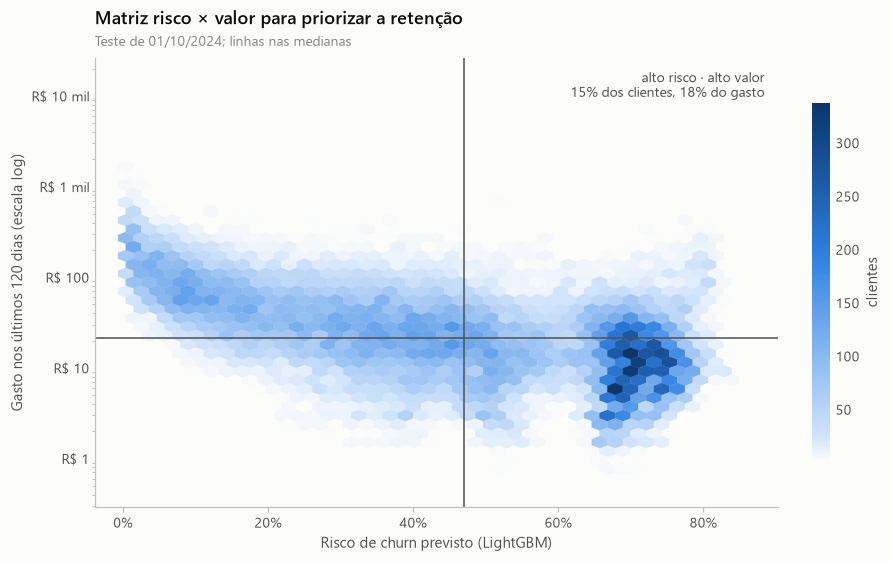

,clientes,% do gasto,churn observado
alto risco · alto valor,"0,149","0,180","0,718"
alto risco · baixo valor,"0,351","0,081","0,738"
baixo risco · alto valor,"0,351","0,696","0,287"
baixo risco · baixo valor,"0,148","0,043","0,423"


In [30]:
alto_risco = teste_C["risco"] >= teste_C["risco"].median()
alto_valor = teste_C["gasto_total"] >= teste_C["gasto_total"].median()
quadrantes = pd.DataFrame({
    "clientes": [((alto_risco == r) & (alto_valor == v)).mean() for r in (True, False) for v in (True, False)],
    "% do gasto": [teste_C.loc[(alto_risco == r) & (alto_valor == v), "gasto_total"].sum() / teste_C["gasto_total"].sum()
                   for r in (True, False) for v in (True, False)],
    "churn observado": [teste_C.loc[(alto_risco == r) & (alto_valor == v), "churn"].mean() for r in (True, False) for v in (True, False)],
}, index=["alto risco · alto valor", "alto risco · baixo valor", "baixo risco · alto valor", "baixo risco · baixo valor"])

fig, ax = plt.subplots(figsize=(8, 5))
hb = ax.hexbin(teste_C["risco"], teste_C["gasto_total"], yscale="log", gridsize=40, cmap=viz.CMAP_SEQ, mincnt=1, linewidths=0.2)
ax.axvline(teste_C["risco"].median(), color=viz.TINTA_2, linewidth=1)
ax.axhline(teste_C["gasto_total"].median(), color=viz.TINTA_2, linewidth=1)
ax.yaxis.set_major_formatter(viz.BRL)
ax.xaxis.set_major_formatter(viz.PCT)
ax.set_xlabel("Risco de churn previsto (LightGBM)")
ax.set_ylabel("Gasto nos últimos 120 dias (escala log)")
ax.grid(False)
cb = fig.colorbar(hb, ax=ax, shrink=0.8)
cb.set_label("clientes", color=viz.TINTA_2)
cb.outline.set_visible(False)
lin = quadrantes.loc["alto risco · alto valor"]
ax.text(0.98, 0.97, f"alto risco · alto valor\n{viz.fmt_pct(lin['clientes'])} dos clientes, {viz.fmt_pct(lin['% do gasto'])} do gasto",
        transform=ax.transAxes, ha="right", va="top", fontsize=9, color=viz.TINTA_2)
viz.titulo(ax, "Matriz risco × valor para priorizar a retenção", "Teste de 01/10/2024; linhas nas medianas")
viz.salvar(fig, "mod_risco_valor")
plt.show()
quadrantes

Os 10% de clientes com maior risco churnam 1,5 vez mais que a média, e contatar os 30% de maior risco alcança cerca de
45% dos churners. Mas o risco é inversamente ligado ao valor: o decil de **menor** risco concentra um terço do gasto.
A matriz risco × valor ajuda a priorizar: o quadrante de alto risco e alto valor reúne 15% dos clientes e 18% do gasto
da base ativa — o alvo natural de uma ação de retenção personalizada, enquanto o grande grupo de alto risco e baixo
valor (em geral clientes de visita única) pede ações baratas e em escala.

## 9. Conclusões

**Critério.** Não há limiar natural de inatividade (H1); τ = 90 dias equilibra falsos churns e atraso de detecção
e é compatível com seis snapshots mensais. A prevalência resultante é de ~53%.

**Predição (H10).** Na validação fora do tempo (dobra C), LightGBM e regressão logística atingem AUC ≈ 0,770,
contra 0,763 do BG/NBD e 0,610 da heurística de recência. O ganho sobre o BG/NBD é pequeno, mas consistente
(+0,007; IC 95% entre +0,006 e +0,009). Três lições:

1. **O que importa é a informação, não o algoritmo**: logística ≈ random forest ≈ LightGBM; sem os atributos de
   histórico acumulado o LightGBM cai para 0,729, abaixo do BG/NBD.
2. **Empilhar snapshots é essencial**: com um único corte de treino (dobra A) o LightGBM fica abaixo do BG/NBD; com três,
   passa à frente.
3. **A heurística de recência é fraca** nesta base: entre clientes ativos, há pouca variação de recência que já não
   seja explicada pela frequência.

**Hipóteses.**

| Hipótese | Evidência | Veredito |
|---|---|---|
| H1 — não há corte natural | probabilidade de retorno cai continuamente com a inatividade (EDA) | apoiada |
| H2 — ordenação robusta a τ | prevalência varia ~8 p.p.; Spearman ≥ 0,96; matriz cruzada estável; topo 10% com 53–65% de sobreposição | apoiada (com ressalva no topo da lista) |
| H3 — atraso relativo > recência | pior isoladamente (AUC 0,545 × 0,592 entre 3+ visitas); no modelo multivariado o AIC é um pouco melhor com a recência absoluta; bloco de ritmo sem informação única | **não apoiada** |
| H4 — frequência e estágio | churn de 68% a 2% conforme visitas; RC 0,49 por DP; principal bloco na ablação (−0,041 de AUC) | apoiada (efeito dominante) |
| H5 — regularidade | RC 1,04 por DP entre 3+ visitas (p ≈ 0,04); curvas quase planas; sem informação única | fraca |
| H6 — defecção parcial | gasto em queda → mais churn (RC 0,92 por DP para tendência do gasto); sem informação única | apoiada, efeito pequeno |
| H7 — amplitude | mais categorias → menos churn dentro dos estratos (RC 0,91 por DP); sem informação única | apoiada, efeito pequeno |
| H8 — sazonalidade | bacalhau → mais churn (RC 1,07 por DP); compradores da Páscoa somem e 1 em 4 volta no Natal | apoiada |
| H9 — valor monetário fraco | ticket sem efeito no modelo geral (p = 0,19); pequeno efeito protetor entre recorrentes | apoiada |
| H10 — aprendizado de máquina > baselines | +0,16 de AUC sobre a recência e +0,007 sobre o BG/NBD (IC 95% exclui zero) | apoiada, com ganho moderado |

Em resumo: **quantas vezes e há quanto tempo o cliente compra** explica quase todo o risco previsível. Os demais
comportamentos têm associação estatística com o churn (úteis para entender e agir), mas pouca informação preditiva
adicional — a distinção entre explicar e prever de Shmueli (2010).

**Limitações.**

* **Recorte de 59 SKUs:** a inatividade é medida só nesses produtos; um cliente pode continuar comprando outros itens
  da loja e aparecer como churn aqui. Compras sem identificação do cliente não aparecem na base.
* **Um único ano:** truncagem à esquerda da antiguidade, poucos snapshots e nenhum ciclo sazonal completo observado
  (a sazonalidade aparece como deriva de calibração no 4º trimestre).
* O desconto é inferido pelo preço relativo à mediana do SKU no mês, sem dados de promoção.

**Próximos passos.** Validar com dados de 2025 (um ciclo sazonal completo fora do tempo); recalibrar as
probabilidades periodicamente; modelar o tempo até a inatividade (sobrevivência) para não depender de um τ fixo;
escolher o tamanho da campanha por critério de lucro (Verbraken, Verbeke & Baesens, 2013); e, havendo dados de
campanhas, migrar de "quem vai sair" para "quem responde à ação" (modelos de *uplift*; Ascarza, 2018).